In [20]:
# TASK 1

import pandas as pd
import requests 
import matplotlib.pyplot as plt

In [21]:
with open("frost_client_id.txt", "r") as file:
    client_id = file.read().strip()

In [31]:
endpoint = "https://frost.met.no/observations/v0.jsonld"

parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

response = requests.get(
    endpoint,
    params=parameters,
    auth=(client_id, "")
)

print(response.status_code)

json_data = response.json()



200


In [33]:
rows = []

for item in json_data.get("data"):
    rows.append({
        "date": item["referenceTime"],
         "temperature": item["observations"][0]["value"]
    })

df_temp = pd.DataFrame(rows)

df_temp["date"] = pd.to_datetime(df_temp["date"])

df_temp.head()




,date,temperature
0,2025-01-01 00:00:00+00:00,-5.2
1,2025-01-02 00:00:00+00:00,-11.5
2,2025-01-03 00:00:00+00:00,-8.9
3,2025-01-04 00:00:00+00:00,-15.5
4,2025-01-05 00:00:00+00:00,-12.5


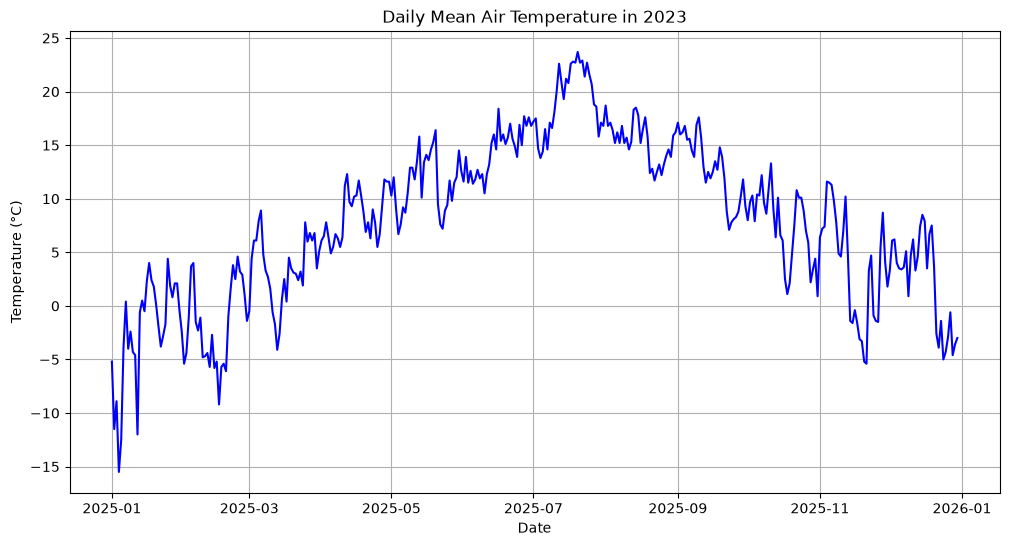

In [34]:
plt.figure(figsize=(12, 6))

plt.plot(
    df_temp["date"],
    df_temp["temperature"],
    color='blue'
)
plt.title("Daily Mean Air Temperature in 2023")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True)

plt.show()

In [38]:
summary = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Minimum", 
"Maximum"],
     "Temperature": [
        df_temp["temperature"].mean(),
        df_temp["temperature"].median(),
        df_temp["temperature"].min(),
        df_temp["temperature"].max()
     ]
})

summary

,Statistic,Temperature
0,Mean,7.902747
1,Median,8.400000
2,Minimum,-15.500000
3,Maximum,23.700000


In [40]:
# TASK 2
parameters = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2025-12-31"
}

response = requests.get(
    endpoint,
    params=parameters,
    auth=(client_id, "")
)

print(response.status_code)

json_data = response.json()


SyntaxError: unterminated string literal (detected at line 4) (2473783471.py, line 4)

In [ ]:
rows = []

for item in json_data.get("data"):
    rows.append({
        "date": item["referenceTime"],
        "precipitation": item["observations"][0]["value"]
    })

df_precip = pd.DataFrame(rows)

df_precip["date"] = pd.to_datetime(df_precip["date"])

df_precip.head()


In [ ]:
combined = pd.merge(
    df_temp,
    df_precip,
    on="date",
)

combined.head()


In [ ]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(
    combined["date"],
    combined["temperature"]
    color="red"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)", color="red")

ax2 = ax1.twinx()

ax2.bar(
    combined["date"],
    combined["precipitation"],
    color="blue",
    alpha=0.5
)
ax2.set_ylabel("Precipitation (mm)", color="blue")

plt.title("Temperature and Precipitation in 2023")

plt.show()



In [ ]:
# TASK 3
parameters = {
    "sources": "SN17850",   
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2023-12-31"
}

response = requests.get(
    endpoint,
    params=parameters,
    auth=(client_id, "")
)

json_data = response.json()


In [ ]:
rows = []

for item in json_data["data"]:
    rows.append({
        "date": item["referenceTime"],
        "temperature": item["observations"][0]["value"]
    })

df_1975 = pd.DataFrame(rows)

df_1925["date"] = pd.to_datetime(df_1975["date"])

df_1925.head()


In [ ]:
df_temp["day"] = range(1, len(df_temp) + 1)

df_1925["day"] = range(1, len(df_1975) + 1)


In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    df_temp["day"],
    df_temp["temperature"]
    label="2023"
)

plt.plot(
    df_1925["day"],
    df_1925["temperature"],
    label="1925"
)

plt.title("Temperature Comparison: 2023 vs 1925")
plt.xlabel("Day of the Year")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)

plt.show()


In [ ]:
comparison_summary = pd.DataFrame({
    "Statistics": ["Mean", "Median", "Minimum", 
"Maximum"],

    "2023": [
        df_temp["temperature"].mean(),
        df_temp["temperature"].median(),
        df_temp["temperature"].min(),
        df_temp["temperature"].max()
    ],

    "1925": [
        df_1925["temperature"].mean(),
        df_1925["temperature"].median(),
        df_1925["temperature"].min(),
        df_1925["temperature"].max()
    ]
})

comparison_summary

